# S³ semantic-axis smoke test

This exploratory test fits Turftopic S³ to the existing semantic passages using the saved BGE-M3 vectors. Passage embeddings are loaded from disk and passed through `embeddings=`; they are not recomputed. The matching local BGE model is used only for vocabulary-term embeddings.

This fit uses 15 components and seed 43. Scores are signed ICA coordinates, not calibrated probabilities or BERTopic topics. Review the displayed positive/negative evidence before interpreting an axis. Original BERTopic assignments are not changed.

Run from the repository root with `uv run --group topic-analysis jupyter lab`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from turftopic import SemanticSignalSeparation

project_root = Path.cwd().resolve()
if not (project_root / 'data/topic-analysis').exists():
    project_root = project_root.parent
if not (project_root / 'data/topic-analysis').exists():
    raise FileNotFoundError('Could not locate data/topic-analysis from the notebook working directory')
results = project_root / 'data/topic-analysis/results'
dataset_path = results / 'segment-dataset/all-segments.parquet'
embedding_path = results / 'jev-semantic-all/bubble-maps/segment-embeddings.npy'
embedding_manifest_path = results / 'jev-semantic-all/bubble-maps/embedding-manifest.json'
model_manifest_path = results / 'segment-dataset/manifest.json'
MODEL_ID = 'BAAI/bge-m3'
MODEL_REVISION = '5617a9f61b028005a4858fdac845db406aefb181'
N_COMPONENTS, RANDOM_STATE = 15, 43
print(f'Project: {project_root}')
print(f'Saved vectors: {embedding_path}')

Project: C:\Users\risto\projects\arvamusfestivali_salvestused
Saved vectors: C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\bubble-maps\segment-embeddings.npy


C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\_snmf.py:20: UserWarning: JAX not found, continuing with NumPy implementation.
  warnings.warn("JAX not found, continuing with NumPy implementation.")


In [2]:
wanted = ['segment_key', 'segmentation', 'passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength']
available = set(pd.read_parquet(dataset_path).columns)
all_passages = pd.read_parquet(dataset_path, columns=[c for c in wanted if c in available])
passages = all_passages.loc[all_passages.segmentation == 'semantic'].reset_index(drop=True)
embedding_manifest = json.loads(embedding_manifest_path.read_text(encoding='utf-8'))
model_info = json.loads(model_manifest_path.read_text(encoding='utf-8'))['models']['semantic']
embeddings = np.load(embedding_path, allow_pickle=False)
assert model_info['embedding_model_id'] == MODEL_ID
assert model_info['embedding_revision'] == MODEL_REVISION
assert int(model_info['embedding_dimension']) == 1024
assert passages.segment_key.tolist() == embedding_manifest['segment_keys'], 'Passage/vector order mismatch'
assert embeddings.shape == (len(passages), 1024), embeddings.shape
assert embeddings.dtype == np.float32 and np.isfinite(embeddings).all()
assert np.allclose(np.linalg.norm(embeddings, axis=1), 1.0, atol=1e-4), 'Vectors are not L2-normalized'
print(f'Validated {len(passages):,} passages × {embeddings.shape[1]} dimensions; float32, finite, L2-normalized.')
print(f"Model: {model_info['embedding_model_id']} @ {model_info['embedding_revision']}")
print(f"Original BERTopic outliers (topic -1): {(passages.topic_id == -1).sum():,}")

Validated 4,132 passages × 1024 dimensions; float32, finite, L2-normalized.
Model: BAAI/bge-m3 @ 5617a9f61b028005a4858fdac845db406aefb181
Original BERTopic outliers (topic -1): 827


## Fit on the precomputed vectors

The encoder is loaded from local cache only. If that exact revision is not cached, the cell fails instead of downloading or substituting another model. Turftopic receives the corpus matrix directly via `embeddings=embeddings`.

In [3]:
encoder = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, local_files_only=True)
s3 = SemanticSignalSeparation(n_components=N_COMPONENTS, encoder=encoder, vectorizer=CountVectorizer(max_features=500), random_state=RANDOM_STATE)
scores = s3.fit_transform(passages.text.tolist(), embeddings=embeddings)
assert scores.shape == (len(passages), N_COMPONENTS), scores.shape
assert np.isfinite(scores).all(), 'S³ scores contain non-finite values'
score_columns = [f's3_component_{i}' for i in range(N_COMPONENTS)]
scored_passages = passages.copy()
for i, column in enumerate(score_columns):
    scored_passages[column] = scores[:, i]
print(f'S³ fit passed: {len(passages):,} passages, {N_COMPONENTS} components, seed {RANDOM_STATE}.')
print('Passage vectors came from disk; no passage re-embedding was run.')

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Output()

[17:59:51] Decomposition done.                                                                        ]8;id=500800;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=94161;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#156\156]8;;\

[17:59:52] Term extraction done.                                                                      ]8;id=576809;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=546940;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#159\159]8;;\

[17:59:57] Vocabulary encoded.                                                                        ]8;id=644119;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=675393;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#169\169]8;;\

           Model fitting done.                                                                        ]8;id=160027;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=785813;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#189\189]8;;\

S³ fit passed: 4,132 passages, 15 components, seed 43.
Passage vectors came from disk; no passage re-embedding was run.


## S³ component summary and naming evidence

S³ returns continuous bipolar axes, not discrete topic assignments. The dominant-axis count below is only an exploratory tally: each passage is counted under the component with its largest absolute standardized score. It is not a cluster count or a calibrated classification. For naming, review Turftopic's high/low term lists alongside the positive/negative extreme passages below, then enter a human-reviewed bipolar label; no labels are generated automatically.

In [4]:
score_frame = pd.DataFrame(scores, columns=score_columns)
score_std = score_frame.std(ddof=0).replace(0, 1)
score_z = (score_frame - score_frame.mean()) / score_std
dominant_component_index = np.abs(score_z.to_numpy()).argmax(axis=1)
dominant_counts = pd.Series(dominant_component_index).value_counts().reindex(range(N_COMPONENTS), fill_value=0)
positive_terms = s3.get_top_words(top_k=12, positive=True)
negative_terms = s3.get_top_words(top_k=12, positive=False)

component_stats = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'passage_count': len(score_frame),
    'score_nan_count': score_frame.isna().sum().to_numpy(),
    'positive_score_count': score_frame.gt(0).sum().to_numpy(),
    'negative_score_count': score_frame.lt(0).sum().to_numpy(),
    'mean_score': score_frame.mean().to_numpy(),
    'score_std': score_frame.std(ddof=0).to_numpy(),
    'min_score': score_frame.min().to_numpy(),
    'max_score': score_frame.max().to_numpy(),
    'dominant_axis_passages_exploratory': dominant_counts.to_numpy(),
})
print(f'S³ passages scored: {len(score_frame):,}; missing passage texts: {passages.text.isna().sum():,}; blank passage texts: {(passages.text.notna() & passages.text.astype("string").str.strip().eq("")).sum():,}')
print('Continuous score distribution and exploratory dominant-axis counts (not topic membership)')
display(component_stats)

axis_review = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'positive_end_terms': [', '.join(words) for words in positive_terms],
    'negative_end_terms': [', '.join(words) for words in negative_terms],
    'reviewed_bipolar_label': ['' for _ in range(N_COMPONENTS)],
    'review_notes': ['' for _ in range(N_COMPONENTS)],
})
print('Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.')
display(axis_review)
assert int(component_stats.passage_count.iloc[0]) == len(passages)
assert int(component_stats.score_nan_count.sum()) == int(score_frame.isna().sum().sum())
assert int(component_stats.dominant_axis_passages_exploratory.sum()) == len(passages)
print(f"S3_COMPONENT_STATS_OK passages={len(passages):,}; components={N_COMPONENTS}; missing_scores={int(score_frame.isna().sum().sum())}")

S³ passages scored: 4,132; missing passage texts: 0; blank passage texts: 0
Continuous score distribution and exploratory dominant-axis counts (not topic membership)


,component_id,passage_count,score_nan_count,positive_score_count,negative_score_count,mean_score,score_std,min_score,max_score,dominant_axis_passages_exploratory
0,0,4132,0,2668,1464,3.101980e-07,1.0,-3.883608,1.940445,319
1,1,4132,0,2193,1939,1.227867e-07,1.0,-3.498074,2.627176,246
2,2,4132,0,1790,2342,-3.914404e-07,1.0,-2.701137,4.695805,262
3,3,4132,0,2014,2118,2.631144e-07,1.0,-2.881600,3.374915,210
4,4,4132,0,2442,1690,7.385668e-08,1.0,-4.308317,2.327197,297
5,5,4132,0,1806,2326,-2.289557e-07,1.0,-2.867026,4.704874,291
6,6,4132,0,2080,2052,3.471264e-07,1.0,-3.725976,3.978580,243
7,7,4132,0,2096,2036,3.028124e-07,1.0,-4.264233,3.559720,268
8,8,4132,0,2224,1908,-3.692834e-08,1.0,-3.997151,2.911896,279
9,9,4132,0,2006,2126,-2.520359e-07,1.0,-3.009374,4.017029,244


Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.


,component_id,positive_end_terms,negative_end_terms,reviewed_bipolar_label,review_notes
0,0,"kooli, koolis, vot, kolm, kuidagi, justkui, as...","hea, ees, selles, hoida, raske, sinna, kaasa, ...",,
1,1,"rääkida, rääkima, räägime, mõttes, mõtlema, ar...","raha, tööle, tööd, selge, palju, töö, lahti, k...",,
2,2,"mitu, muidu, seesama, teed, mingid, juures, mu...","rääkida, räägime, ette, rääkima, eest, räägi, ...",,
3,3,"mingisugune, erinevaid, erinevad, olid, mõned,...","riik, eesti, noor, ees, eestis, eriti, kes, tö...",,
4,4,"mulle, õpetaja, kooli, koolis, minna, mõju, mi...","ai, it, id, aeg, siia, aitäh, asi, iganes, tea...",,
5,5,"tööle, töö, tööd, inimese, inimest, head, inim...","kuhu, teen, eesti, kindlasti, iga, riigi, eest...",,
6,6,"protsenti, kakskümmend, kolmkümmend, aastat, v...","küsida, teha, leida, kõigile, juures, samamood...",,
7,7,"maailma, mõelda, mõtlema, mõju, maailmas, rääg...","läks, jooksul, läinud, kinni, teen, kooli, tag...",,
8,8,"tööle, teame, valmis, tulevad, lähevad, edasi,...","teen, probleem, mul, vad, mulle, pealt, selgel...",,
9,9,"riigi, arutelu, riik, vot, kellel, jääb, ütles...","noor, noh, selles, koolis, oled, uus, ehk, tun...",,


S3_COMPONENT_STATS_OK passages=4,132; components=15; missing_scores=0


## 2-D view of the S³ axes

Each panel shows the same passage map: a PCA projection of the already-saved embeddings. Color shows the signed standardized S³ score for that panel's axis; outlined points are original BERTopic outliers (`topic_id == -1`). The map is only a 2-D projection and does not define clusters or topics.

The table below gives one strongest positive and negative evidence passage per axis, alongside top terms. These are evidence for human review, not automatic topic names.

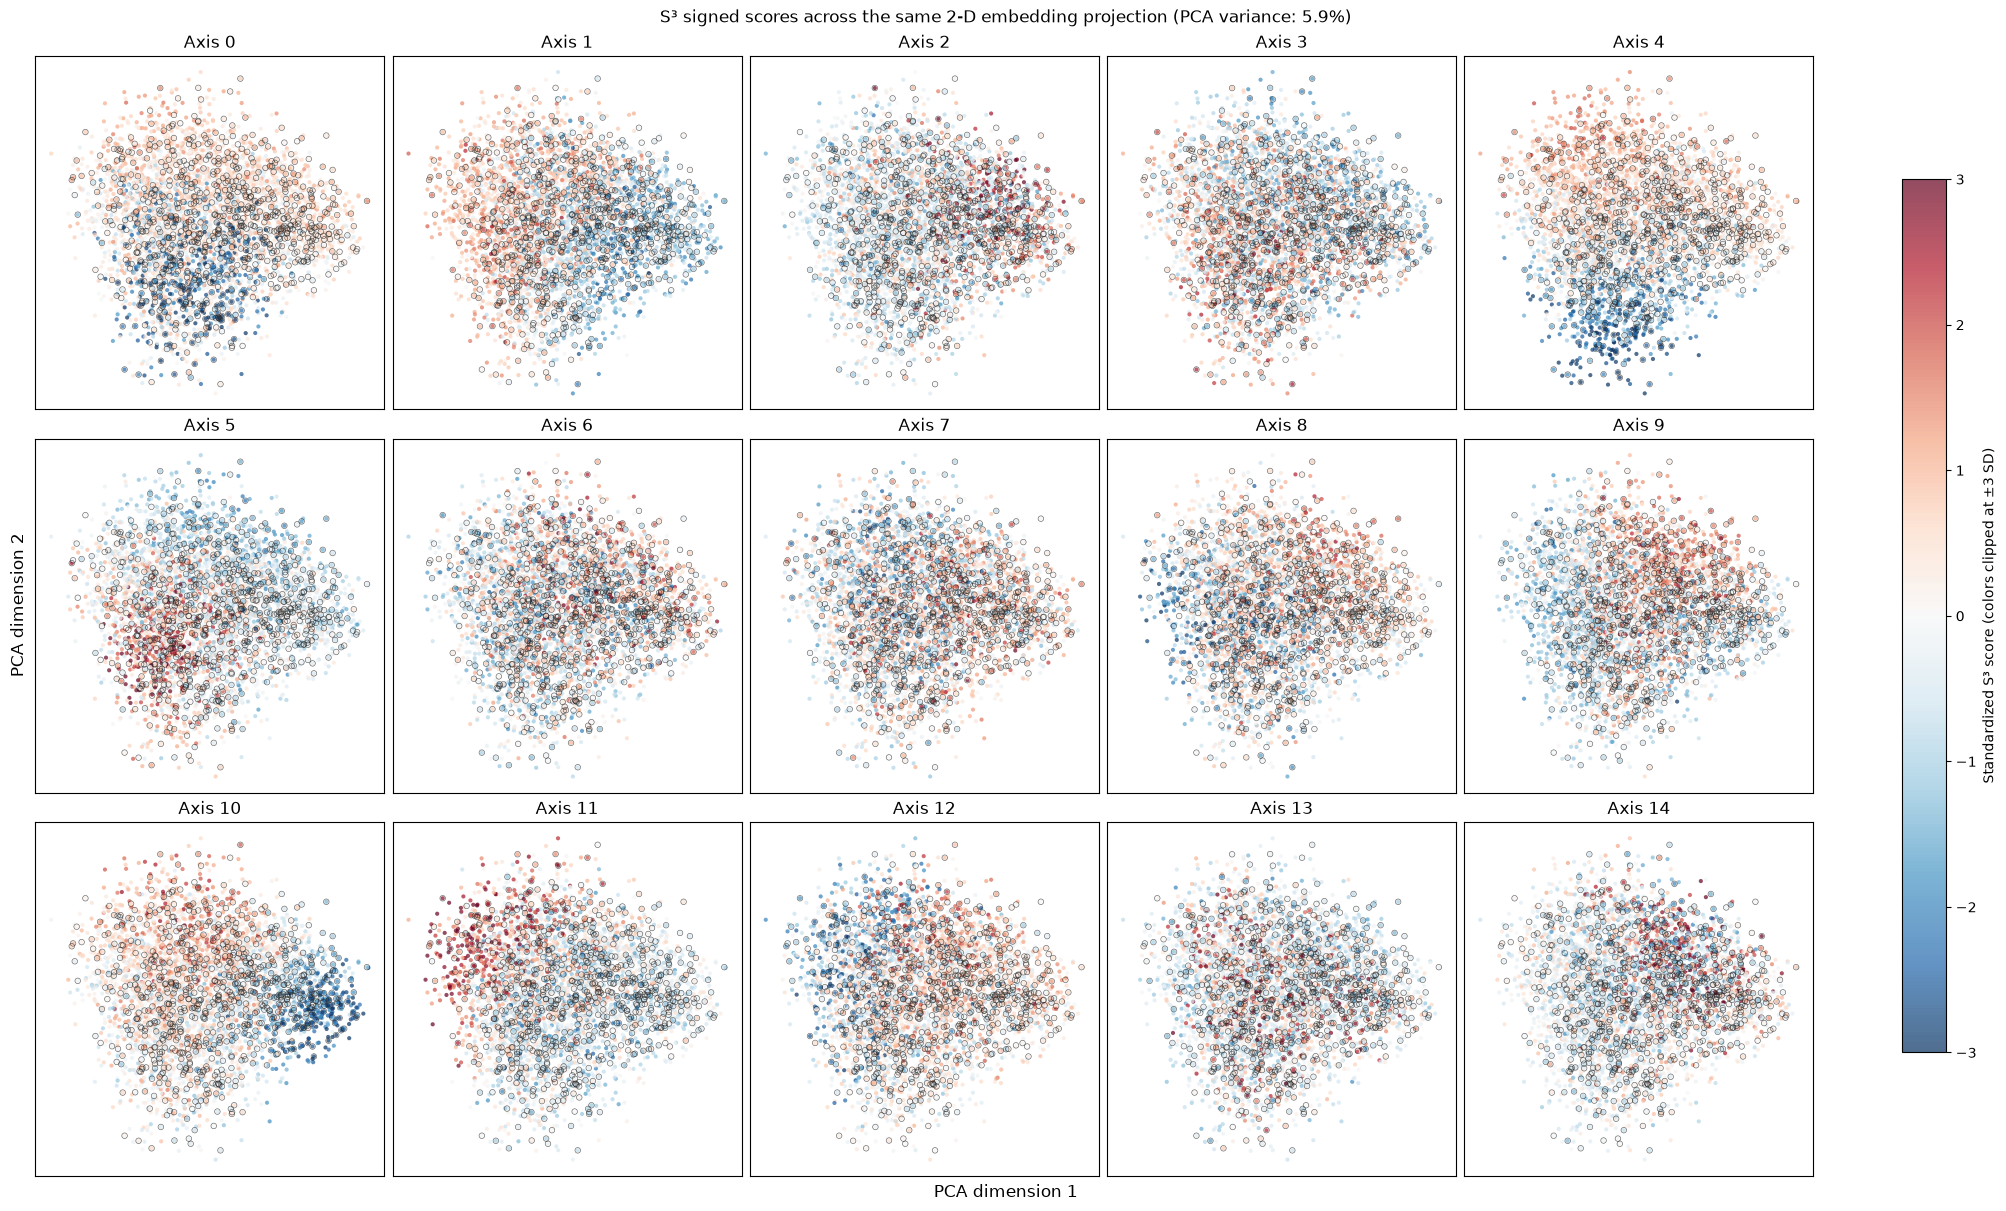

2-D projection uses the saved 1024-D vectors for 4,132 passages; BERTopic outliers outlined: 827.
Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.


,axis,positive terms,positive passage,negative terms,negative passage
0,0,"kooli, koolis, vot, kolm, kuidagi, justkui, as...",2280202454 | Oskusi kombineerides saame tõenäo...,"hea, ees, selles, hoida, raske, sinna, kaasa, ...",2397177255 | Vabakutseliste loovisikute toimet...
1,1,"rääkida, rääkima, räägime, mõttes, mõtlema, ar...","2302899446 | Kuidas planeerida tuuleparke nii,...","raha, tööle, tööd, selge, palju, töö, lahti, käib",2400184989 | Tiigri üleandmine. Kes kannab Ees...
2,2,"mitu, muidu, seesama, teed, mingid, juures, mu...",2267420990 | Püsimetsandus – kas kesktee metsa...,"rääkida, räägime, ette, rääkima, eest, räägi, ...","2396670933 | Kui pole mugav, siis ei kaasa_! |..."
3,3,"mingisugune, erinevaid, erinevad, olid, mõned,...",2277338243 | Maailmahariduslik mälumäng ja mõt...,"riik, eesti, noor, ees, eestis, eriti, kes, töö",2247188684 | Kas kiirustades elad kauem? | 450...
4,4,"mulle, õpetaja, kooli, koolis, minna, mõju, mi...",2393585472 | Kas lapsel on päriselt koht Eesti...,"ai, it, id, aeg, siia, aitäh, asi, iganes",2289585026 | Kuidas kaitsta lapsi AI-ajastul i...
5,5,"tööle, töö, tööd, inimese, inimest, head, inim...",2247188693 | Töökius otse laval | 2700.8–3091....,"kuhu, teen, eesti, kindlasti, iga, riigi, eest...","2400184980 | Eesti, Singapur, Dubai, Delaware...."
6,6,"protsenti, kakskümmend, kolmkümmend, aastat, v...",2293106222 | Süstime rahva saledaks_ | 374.8–5...,"küsida, teha, leida, kõigile, juures, samamood...",2258666741 | Me paneme selle muuseumi kinni! |...
7,7,"maailma, mõelda, mõtlema, mõju, maailmas, rääg...",2250797873 | Vasakpoolsus Eestis. Kas turumõtl...,"läks, jooksul, läinud, kinni, teen, kooli, tag...",2396692743 | Järgmise põlvkonna õpilasmalev | ...
8,8,"tööle, teame, valmis, tulevad, lähevad, edasi,...",2247188708 | Disainime tööd | 1480.04–1710.64s...,"teen, probleem, mul, vad, mulle, pealt, selgel...",2289585026 | Kuidas kaitsta lapsi AI-ajastul i...
9,9,"riigi, arutelu, riik, vot, kellel, jääb, ütles...",2323554791 | Parlamendierakondade esimeeste de...,"noor, noh, selles, koolis, oled, uus, ehk, tunne",2397264567 | Teadmussiirdedoktorantuur – Eesti...


In [5]:
projection = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit_transform(embeddings)
assert projection.shape == (len(passages), 2) and np.isfinite(projection).all()
projection_variance = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit(embeddings).explained_variance_ratio_.sum()
outlier_mask = passages.topic_id.eq(-1).to_numpy()
ncols = min(5, N_COMPONENTS)
nrows = (N_COMPONENTS + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), sharex=True, sharey=True, constrained_layout=True)
axes = np.asarray(axes).reshape(-1)
for component_id, ax in enumerate(axes):
    if component_id >= N_COMPONENTS:
        ax.set_visible(False)
        continue
    values = score_z.iloc[:, component_id].to_numpy()
    ax.scatter(projection[:, 0], projection[:, 1], c=values, cmap='RdBu_r', vmin=-3, vmax=3, s=9, alpha=0.7, linewidths=0, rasterized=True)
    ax.scatter(projection[outlier_mask, 0], projection[outlier_mask, 1], facecolors='none', edgecolors='#222222', s=16, linewidths=0.45, alpha=0.7, rasterized=True)
    ax.set_title(f'Axis {component_id}')
    ax.set_xticks([]); ax.set_yticks([])
fig.supxlabel('PCA dimension 1'); fig.supylabel('PCA dimension 2')
fig.suptitle(f'S³ signed scores across the same 2-D embedding projection (PCA variance: {projection_variance:.1%})')
fig.colorbar(axes.flat[0].collections[0], ax=axes.ravel().tolist(), label='Standardized S³ score (colors clipped at ±3 SD)', shrink=0.78)
plt.show()

assert len(score_z.columns) == N_COMPONENTS
assert len(projection) == len(passages) == len(scored_passages)
assert int(outlier_mask.sum()) == int((passages.topic_id == -1).sum())
print(f'2-D projection uses the saved {embeddings.shape[1]}-D vectors for {len(passages):,} passages; BERTopic outliers outlined: {outlier_mask.sum():,}.')

table_rows = []
for component_id, score_column in enumerate(score_columns):
    positive = scored_passages[score_column].idxmax()
    negative = scored_passages[score_column].idxmin()
    pos = scored_passages.loc[positive]
    neg = scored_passages.loc[negative]
    table_rows.append({
        'axis': component_id,
        'positive terms': ', '.join(positive_terms[component_id][:8]),
        'positive passage': f"{pos.get('episode_id', '')} | {pos.get('title', '')} | {pos.get('start_seconds', '')}–{pos.get('end_seconds', '')}s | BERTopic {pos.get('topic_id', '')} | score {pos[score_column]:.3f} | {pos.get('text', '')}",
        'negative terms': ', '.join(negative_terms[component_id][:8]),
        'negative passage': f"{neg.get('episode_id', '')} | {neg.get('title', '')} | {neg.get('start_seconds', '')}–{neg.get('end_seconds', '')}s | BERTopic {neg.get('topic_id', '')} | score {neg[score_column]:.3f} | {neg.get('text', '')}",
    })
axis_evidence_table = pd.DataFrame(table_rows)
assert len(axis_evidence_table) == N_COMPONENTS
print('Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.')
display(axis_evidence_table)

In [6]:
evidence_columns = [c for c in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if c in scored_passages.columns]
for i, score_column in enumerate(score_columns):
    print(f'Component {i}: highest-scoring passages')
    display(scored_passages.nlargest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
    print(f'Component {i}: lowest-scoring passages')
    display(scored_passages.nsmallest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
outliers = scored_passages.loc[scored_passages.topic_id == -1].copy()
outlier_view = outliers[evidence_columns + score_columns].sort_values(score_columns[0], key=lambda x: x.abs(), ascending=False)
print(f'Outliers shown for additional evidence review: {len(outliers):,} total; first 12 by absolute component-0 score.')
display(outlier_view.head(12).reset_index(drop=True))

Component 0: highest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2280202454:000000663720-000000827240,2280202454,Oskusi kombineerides saame tõenäolisemalt olüm...,663.72,827.24,Kood/Jõhvist. Ilmselt siis mingisuguse sildiga...,28,0.701535,1.940445
1,2395857126:000003272160-000003368480,2395857126,Kuuluvustunne või äärmuslus_ Kuidas ennetada r...,3272.16,3368.48,"ütleme, et need siiamaani koristame. Aga mis p...",232,1.000000,1.829471
2,2277338246:000003211520-000003408080,2277338246,Ettevõtjad ja noored - kas parallelmaailmad võ...,3211.52,3408.08,"Eesti koolile, vaid kogu ühiskonnale see, kuid...",68,0.333291,1.791703


Component 0: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2397177255:000002217680-000002352520,2397177255,Vabakutseliste loovisikute toimetulek,2217.68,2352.52,"Et noh, homme mul on näiteks vähiteemaline deb...",2,0.966427,-3.883608
1,2394248502:000003893920-000004342040,2394248502,Vähitõrje järgmised viis aastat – mida peab Ee...,3893.92,4342.04,ti patsiendini jõuab. Et ma ei tea kunagi ära ...,2,0.374107,-3.818166
2,2400207750:000002963880-000003396320,2400207750,Eesti terviseandmed_ kristallkuul või kompass_,2963.88,3396.32,", et kas asjad läksid pärast paremaks või ei l...",-1,NaN,-3.766230


Component 1: highest-scoring passages


...

,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_14
0,2314163834:000000208000-000000439440,2314163834,Kilud versus karud - Läänemeremaade koostöö tu...,208.00,439.44,Venemaa täiemahuline agressioonisõda Ukrainas ...,29,0.387974,4.909205
1,2314163834:000002500040-000003093000,2314163834,Kilud versus karud - Läänemeremaade koostöö tu...,2500.04,3093.00,Viimastel kuudel on palju juttu olnud Ukraina ...,29,0.186300,4.875753
2,2271676346:000000561160-000000889120,2271676346,Ajateenistuse tulevikuvaade – kuhu liigume ja ...,561.16,889.12,alistlikud eesmärgid ei ole mitte kuidagi muut...,189,1.000000,4.700503


Component 14: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_14
0,2396670921:000001061120-000001457240,2396670921,Kas Eesti tulevik on parkla või meeldiv elukes...,1061.12,1457.24,"Ja et siin kõlas alguses, et, et sellest probl...",-1,NaN,-2.662271
1,2397829638:000000461280-000000848680,2397829638,Kus on noore kodu_ Kuidas elatakse tulevikus j...,461.28,848.68,"selle kõrval, et üks asi on see, et kas seda o...",-1,NaN,-2.478204
2,2397829638:000002691600-000003045160,2397829638,Kus on noore kodu_ Kuidas elatakse tulevikus j...,2691.60,3045.16,gete karpide piirkondades ja Lasnamäel ja Must...,-1,NaN,-2.470775


Outliers shown for additional evidence review: 827 total; first 12 by absolute component-0 score.


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0,s3_component_1,...,s3_component_5,s3_component_6,s3_component_7,s3_component_8,s3_component_9,s3_component_10,s3_component_11,s3_component_12,s3_component_13,s3_component_14
0,2400207750:000002963880-000003396320,2400207750,Eesti terviseandmed_ kristallkuul või kompass_,2963.88,3396.32,", et kas asjad läksid pärast paremaks või ei l...",-1,NaN,-3.766230,0.469666,...,0.537624,1.296647,-0.523221,0.689764,-0.571452,0.026063,-0.124966,0.409240,-0.442327,-0.280721
1,2400207756:000000958880-000001123240,2400207756,Kuhu kaovad töötajad_,958.88,1123.24,"nii-öelda tervena või, või ütleme nagu täiskoo...",-1,NaN,-3.681273,-0.914738,...,-0.790712,-0.676488,-0.371921,0.670344,0.169291,-0.393747,-0.406973,-0.031554,-0.506670,0.270199
2,2293106219:000005118320-000005347560,2293106219,Ravivalikute loterii - miks mõni haigus saab k...,5118.32,5347.56,"na arstina, praktiseeriva arstina soovitaksid ...",-1,NaN,-3.664407,-0.729284,...,-0.563840,-1.015242,0.384176,0.772851,0.569570,0.178282,0.241846,-0.995424,-0.598145,-0.425683
3,2293106219:000001661280-000002057120,2293106219,Ravivalikute loterii - miks mõni haigus saab k...,1661.28,2057.12,"isukohti ju meedias, et võib-olla me peaksime ...",-1,NaN,-3.630188,-2.284472,...,-1.148927,0.929753,0.463829,-0.690775,0.618661,1.236622,0.050612,-0.190431,-0.803585,0.015400
4,2400207750:000001865200-000002116960,2400207750,Eesti terviseandmed_ kristallkuul või kompass_,1865.20,2116.96,", kes no kuidagi ei leia neid enda terviseandm...",-1,NaN,-3.611005,0.698849,...,-0.135995,-0.536264,-1.687281,0.521702,0.303470,0.293055,-0.050756,1.076560,-0.436900,-0.417866
5,2400207750:000004078800-000004469040,2400207750,Eesti terviseandmed_ kristallkuul või kompass_,4078.80,4469.04,"No siin on jälle see, et me ei tee neid uuring...",-1,NaN,-3.522387,0.066191,...,-0.580721,0.189193,-0.089388,0.189659,-0.397728,-0.284579,-0.157899,0.051955,0.061249,0.307906
6,2400207750:000002802840-000002963880,2400207750,Eesti terviseandmed_ kristallkuul või kompass_,2802.84,2963.88,see on nagu neid andmeid küsima hakkad. No sii...,-1,NaN,-3.521613,0.427273,...,0.063639,0.870406,2.276865,0.861262,0.307498,-0.077729,-0.336886,-0.599653,-0.220270,0.350843
7,2394248505:000004138640-000004234280,2394248505,Tehisintellekti tulevik vähiravis,4138.64,4234.28,", et noh. Ma rääkisin nendest patsientidest, k...",-1,NaN,-3.521101,-1.302470,...,-0.430203,0.290879,-1.444880,-0.671794,0.003949,-1.552537,-1.434035,-0.044685,-1.013802,-0.204319
8,2400207762:000005085280-000005273640,2400207762,Kelle vastutus on ennetus tervishoius_,5085.28,5273.64,"tis määratakse. Inimesel, kes ei ole arsti juu...",-1,NaN,-3.426788,0.534311,...,-0.106287,-0.561654,0.456679,1.308721,0.266729,0.309573,0.596773,-0.410040,-0.399601,-0.267783
9,2293106219:000001456360-000001661280,2293106219,Ravivalikute loterii - miks mõni haigus saab k...,1456.36,1661.28,"Aga me ei tohi jõuda sinna välja, kus ühel het...",-1,NaN,-3.390611,-1.044816,...,-0.620161,0.046031,-0.787250,-0.457197,0.379930,-0.081844,-0.728397,0.387415,-1.183354,-0.626805
